# Parte 4 — Resumen Automático de Textos (RAT)

**Proyecto:** Observatorio del discurso presidencial en español
**Corpus:** `unified/presidentes_latam_es.parquet` — 4,531 discursos, 5 hablantes.

Este cuaderno demuestra el resumidor del módulo `rat_scripts/`: toma un discurso (o un texto
cualquiera) y devuelve un resumen extractivo de ~15 % de la longitud original.

| Pieza | Archivo | Temario |
|---|---|---|
| Segmentación y filtrado de unidades | `rat_scripts/units.py` | 4.2, 4.3.2 |
| Representación TF-IDF (IDF global de RI) | `rat_scripts/representation.py` | 4.4.1 |
| Puntuadores (TF-IDF, centroide, Luhn, TextRank, LexRank, LSA) | `rat_scripts/scorers.py` | 4.4.1, 4.4.2, 4.4.6 |
| Pistas discursivas (posición, conectores, título) | `rat_scripts/features.py` | 4.4.4 |
| Selección MMR y generación | `rat_scripts/select.py` | 4.3.3, 4.3.4 |
| Evaluación ROUGE + banco de pruebas | `rat_scripts/evaluate.py` | 4.5 |
| Resumen multi-documento por año | `rat_scripts/multi.py` | 4.6 |

Sin IA generativa, sin deep learning y sin transformers: sólo IDF, álgebra lineal (SVD truncada),
PageRank y MMR. Las fórmulas y la discusión completa están en **`rat_scripts/rat_explained.md`**.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ei_scripts.segment import segment
from ri_scripts import load_index
from ri_scripts.corpus import read_doc
from rat_scripts import (METHODS, all_scores, build_representation, build_units,
                         config, hybrid_score, summarize_doc, summarize_docs,
                         summarize_text)
from rat_scripts.evaluate import (aggregate, evaluate_summary, load_gold,
                                  rouge_l, rouge_n, run_benchmark)
from rat_scripts.features import cue_score, position_score
from rat_scripts.select import select_mmr, target_sentences

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 200)

ix = load_index()
print(f"índice RI: {ix.n_docs} discursos · {ix.vocab_size} términos · avgdl={ix.avgdl:.0f} tokens")
print("parámetros RAT:", {"ratio": config.SUMMARY_RATIO, "MMR λ": config.MMR_LAMBDA,
                          "budget": config.WORD_BUDGET, "pesos": config.WEIGHTS})

índice RI: 4531 discursos · 30083 términos · avgdl=2423 tokens
parámetros RAT: {'ratio': 0.15, 'MMR λ': 0.7, 'budget': 180, 'pesos': {'centroid': 0.28, 'textrank': 0.24, 'discourse': 0.26, 'lsa': 0.1, 'luhn': 0.12}}


## 1. Corpus disponible

El módulo no reindexa nada: usa el mismo `doc_id`, el mismo vocabulario y el mismo IDF global que
el buscador de RI.

In [2]:
filas = []
for speaker, (start, end) in ix.speaker_blocks.items():
    filas.append({
        "hablante": speaker,
        "docs": end - start,
        "desde": min(ix.dates[start:end]),
        "hasta": max(ix.dates[start:end]),
        "tokens indexados": int(ix.dl[start:end].sum()),
        "tokens/doc": round(float(ix.dl[start:end].mean())),
    })
display(pd.DataFrame(filas).sort_values("docs", ascending=False, ignore_index=True))

,hablante,docs,desde,hasta,tokens indexados,tokens/doc
0,Andrés Manuel López Obrador,2294,2018-12-02,2024-09-30,8488220,3700
1,Pedro Sánchez,1136,2018-06-11,2026-04-29,1476379,1300
2,Sebastián Piñera Echenique,884,2018-03-11,2022-03-05,612638,693
3,Javier Milei,187,2023-12-10,2026-04-29,349106,1867
4,Nicolás Maduro,30,2015-07-06,2023-01-24,53875,1796


## 2. Unidades de resumen (temario 4.2 y 4.3.2)

Se reutiliza el segmentador de EI (punkt + cortes por `;` `:` `,`). Luego se aplican los criterios
de extracción: la oración debe tener entre 7 y 75 palabras, contenido léxico (≥ 2 términos tras
quitar stopwords), no ser ruido de transcripción (aplausos, cabeceras, pies de página) y no estar
repetida. Ejemplo con un discurso corto de AMLO:

In [3]:
doc_id = 1065
doc = read_doc(doc_id, ix.corpus_path, ix.offsets)
units = build_units(doc["text"], title=doc["title"])

print(doc["speaker"], "·", doc["date"], "·", doc["title"])
print(f"palabras: {len(doc['text'].split())} · oraciones punkt: {len(segment(doc['text']))} "
      f"· unidades válidas: {len(units)}")

tabla = pd.DataFrame([{
    "#": u.idx, "palabras": u.n_words, "posición": round(u.position, 2),
    "párrafo": u.paragraph, "conector": bool(cue_score(u.text)[0] > 0),
    "texto": u.text,
} for u in units])
display(tabla.head(10))

Andrés Manuel López Obrador · 2021-02-26 · 26.02.21 Versión estenográfica. Inauguración del Hospital General de Querétaro
palabras: 880 · oraciones punkt: 32 · unidades válidas: 27


,#,palabras,posición,párrafo,conector,texto
0,0,34,0.00,0,False,Me da mucho gusto estar de nuevo en esta histórica ciudad de Querétaro y me da más gusto el acompañar al c...
1,1,25,0.04,0,False,"Es muy importante el retomar el camino del desarrollo y del bienestar, que sigamos emulando a los buenos g..."
2,2,17,0.08,0,False,"El anterior hospital se construyó, de acuerdo a lo que nos ha informado el gobernador, en 1963."
3,3,27,0.12,0,False,"En ese entonces gobernaba el licenciado Adolfo López Mateos, él era el presidente de México; y en ese ento..."
4,4,28,0.15,0,False,"Y en ese sexenio y en el siguiente se creció a una tasa promedio anual del seis por ciento, 12 años de cre..."
5,5,23,0.19,0,False,"Se conoce ese periodo como el desarrollo estabilizador, porque se logró ese crecimiento económico sin infl..."
6,6,12,0.23,0,False,"Y en ese entonces, por ese crecimiento se hicieron muchas obras públicas."
7,7,42,0.27,0,False,"En ese entonces fue cuando se inició la electrificación de todo México, cuando con la Comisión Federal de ..."
8,8,35,0.31,0,True,"Con López Mateos, no hay que olvidarlo, se entregó de manera gratuita los libros, se entregaron de manera ..."
9,9,41,0.35,0,True,"Por eso es muy importante el que se esté inaugurando el día de hoy este hospital, que garantiza lo que est..."


`posición` va de 0 (inicio) a 1 (final) y la usa el prior discursivo: en un discurso político el
planteamiento está al inicio y el cierre al final; el centro suele ser digresión.

## 3. Representación: TF-IDF con el IDF **global** del corpus

Cada oración es un vector de términos analizados (stem Snowball, sin stopwords). El peso de cada
término usa el IDF del índice de RI:

$$w_{ij} = \text{tf}_{ij}\cdot \text{idf}_j, \qquad \text{idf}_j = \ln\frac{1+N}{1+\text{df}_j}+1$$

y cada fila se normaliza a norma 1, de modo que el coseno es un producto punto.

In [4]:
rep = build_representation(units, use_global_idf=True)
print(f"oraciones: {rep.n_units} · términos: {rep.n_terms} · IDF: {rep.idf_source}")
print("términos de mayor peso en el discurso:")
for term, weight in rep.top_terms(12):
    print(f"  {term:14s} {weight:6.2f}")

oraciones: 27 · términos: 202 · IDF: global
términos de mayor peso en el discurso:
  queretar         2.58
  hospital         2.49
  medic            1.71
  gust             1.50
  alimon           1.39
  da               1.36
  salud            1.25
  puebl            1.05
  crecimient       1.00
  especial         0.94
  francisc         0.90
  especializ       0.87


## 4. Puntuadores (temario 4.4)

Cada componente puntúa todas las oraciones por un criterio distinto:

- **TF-IDF**: media de los 5 pesos más altos de la oración.
- **Centroide**: $\cos(w_i, c)$ con $c$ la media normalizada de las oraciones del discurso.
- **Luhn**: sólo palabras "significativas" (df entre 5 % y 70 % de las oraciones); puntúa
  $\sum \text{idf}_t/\sqrt{\text{span}}$ (span = distancia entre la primera y la última palabra clave).
- **TextRank**: PageRank ($d=0.85$) sobre el grafo completo de similitud coseno.
- **LexRank**: centralidad de grado sobre el grafo binarizado con umbral $\theta=0.10$.
- **LSA**: SVD truncada de la matriz TF-IDF; masa de la oración en los componentes, ponderada por σ.
- **Discursivo**: $0.5\cdot\pi(\text{posición}) + 0.35\cdot\text{conectores} + 0.15\cdot\text{título}$,
  con penalizaciones por saludos, cortesía, listas y frases que empiezan a media idea.

Veamos qué elige cada uno en el mismo discurso (top-3):

In [5]:
scores = all_scores(rep, doc["title"])
nombres = ["tfidf", "centroid", "luhn", "textrank", "lexrank", "lsa", "discourse"]
filas = []
for name in nombres:
    top = np.argsort(-scores[name])[:3]
    filas.append({"método": name, "top-3 oraciones": " | ".join(f"#{i} {units[i].text[:60]}…" for i in top)})
display(pd.DataFrame(filas))

,método,top-3 oraciones
0,tfidf,"#25 La verdad, me da mucho gusto estar aquí.… | #21 Me da mucho gusto, repito, estar aquí.… | #14 La patri..."
1,centroid,#0 Me da mucho gusto estar de nuevo en esta histórica ciudad de… | #20 Por eso es muy importante decir que...
2,luhn,"#0 Me da mucho gusto estar de nuevo en esta histórica ciudad de… | #23 Y como aquí lo dijo Francisco, lo h..."
3,textrank,#0 Me da mucho gusto estar de nuevo en esta histórica ciudad de… | #20 Por eso es muy importante decir que...
4,lexrank,#20 Por eso es muy importante decir que este es un hospital escu… | #0 Me da mucho gusto estar de nuevo en...
5,lsa,"#23 Y como aquí lo dijo Francisco, lo hicimos ‘al alimón’.… | #25 La verdad, me da mucho gusto estar aquí...."
6,discourse,"#2 El anterior hospital se construyó, de acuerdo a lo que nos h… | #1 Es muy importante el retomar el cami..."


## 5. Híbrido + MMR (temario 4.3.3)

Los componentes se estandarizan (z-score recortado a ±3σ) y se combinan:

$$S(i) = 0.28\,z_{\text{centroid}} + 0.24\,z_{\text{textrank}} + 0.26\,z_{\text{discourse}}
+ 0.10\,z_{\text{lsa}} + 0.12\,z_{\text{luhn}}$$

Después MMR elige greedy, penalizando redundancia y respetando un presupuesto de 180 palabras:

$$\text{MMR}(i) = 0.7\cdot \text{rel}(i) - 0.3\cdot\max_{j\in S}\cos(i,j)$$

In [6]:
relevance = hybrid_score(scores, config.WEIGHTS)
k = target_sentences(len(units))
chosen = select_mmr(relevance, rep.sim, k, units)

tabla = pd.DataFrame([{
    "#": i, "score": round(float(relevance[i]), 3), "palabras": units[i].n_words,
    "texto": units[i].text[:95],
} for i in np.argsort(-relevance)[:9]])
display(tabla)
print("k objetivo:", k, "· elegidas:", chosen)

s = summarize_doc(doc_id, ix=ix)
print("\n" + "=" * 100)
print(s.pretty(width=100))
print("=" * 100)
display(pd.DataFrame(s.sentences)[["rank", "idx", "words", "score", "text"]])
display(pd.Series({k: round(v, 3) for k, v in s.stats.items() if isinstance(v, (int, float))}))

,#,score,palabras,texto
0,0,0.868,34,Me da mucho gusto estar de nuevo en esta histórica ciudad de Querétaro y me da más gusto el aco
1,20,0.810,41,"Por eso es muy importante decir que este es un hospital escuela, que es un hospital de especial"
2,12,0.596,30,"Tenemos que trabajar juntos por la educación, por la salud, por el bienestar de nuestro pueblo"
3,9,0.537,41,"Por eso es muy importante el que se esté inaugurando el día de hoy este hospital, que garantiza"
4,16,0.486,24,"Es un hospital moderno, un hospital escuela, porque, además de atender a pacientes, aquí se van"
5,13,0.457,41,"Cuando el gobernador de Querétaro me invitó a la inauguración dije: Vamos, porque hace falta ma"
6,2,0.433,17,"El anterior hospital se construyó, de acuerdo a lo que nos ha informado el gobernador, en 1963."
7,18,0.422,41,"Antes podían especializarse hasta ocho mil médicos, ahora ya 20 mil médicos van a poder estudia"
8,26,0.419,33,"Yo quiero agradecer también la presencia de los familiares de Francisco, que nos acompañan, y d"


k objetivo: 5 · elegidas: [0, 2, 9, 12, 20]



Andrés Manuel López Obrador 2021-02-26 · hybrid
Me da mucho gusto estar de nuevo en esta histórica ciudad de Querétaro y me da más gusto el
acompañar al ciudadano gobernador de Querétaro, Francisco Domínguez, en la inauguración de este
hospital general. El anterior hospital se construyó, de acuerdo a lo que nos ha informado el
gobernador, en 1963. Por eso es muy importante el que se esté inaugurando el día de hoy este
hospital, que garantiza lo que establece el artículo 4º de la Constitución: el derecho del pueblo a
la salud, atención médica de calidad y medicamentos gratuitos. Tenemos que trabajar juntos por la
educación, por la salud, por el bienestar de nuestro pueblo y eso es lo que se está demostrando en
este acto aquí en Querétaro. Por eso es muy importante decir que este es un hospital escuela, que es
un hospital de especialidades, que es un hospital que va a poder atender a pacientes y que va a
resolver la demanda de atención médica en Querétaro.


,rank,idx,words,score,text
0,1,0,34,0.867510,Me da mucho gusto estar de nuevo en esta histórica ciudad de Querétaro y me da más gusto el acompañar al c...
1,2,20,41,0.809812,"Por eso es muy importante decir que este es un hospital escuela, que es un hospital de especialidades, que..."
2,3,12,30,0.595669,"Tenemos que trabajar juntos por la educación, por la salud, por el bienestar de nuestro pueblo y eso es lo..."
3,4,9,41,0.536765,"Por eso es muy importante el que se esté inaugurando el día de hoy este hospital, que garantiza lo que est..."
4,5,2,17,0.433012,"El anterior hospital se construyó, de acuerdo a lo que nos ha informado el gobernador, en 1963."


n_units             27.000
n_selected           5.000
words_original     880.000
words_summary      163.000
compression          0.185
reduction            0.815
coverage             0.795
redundancy           0.165
mean_sent_words     32.600
dtype: float64

## 6. Los ocho métodos sobre el mismo discurso

`lead` es la línea base trivial (las primeras k oraciones), `random` el azar. Todos usan el mismo
número de oraciones objetivo y el mismo presupuesto de palabras.

In [7]:
filas = []
for method in METHODS:
    sm = summarize_doc(doc_id, ix=ix, method=method)
    filas.append({
        "método": method,
        "oraciones": sm.stats["n_selected"],
        "palabras": sm.stats["words_summary"],
        "compresión": round(sm.stats["compression"], 3),
        "cobertura": round(sm.stats["coverage"], 2),
        "resumen (inicio)": sm.text[:80] + "…",
    })
display(pd.DataFrame(filas))

,método,oraciones,palabras,compresión,cobertura,resumen (inicio)
0,lead,5,131,0.149,0.63,Me da mucho gusto estar de nuevo en esta histórica ciudad de Querétaro y me da m…
1,tfidf,5,45,0.051,0.21,"Y en ese entonces, por ese crecimiento se hicieron muchas obras públicas. Esto n…"
2,centroid,5,179,0.203,0.76,Me da mucho gusto estar de nuevo en esta histórica ciudad de Querétaro y me da m…
3,luhn,5,161,0.183,0.79,Me da mucho gusto estar de nuevo en esta histórica ciudad de Querétaro y me da m…
4,textrank,5,179,0.203,0.76,Me da mucho gusto estar de nuevo en esta histórica ciudad de Querétaro y me da m…
5,lexrank,5,157,0.178,0.76,Me da mucho gusto estar de nuevo en esta histórica ciudad de Querétaro y me da m…
6,lsa,5,98,0.111,0.52,"Con López Mateos, no hay que olvidarlo, se entregó de manera gratuita los libros…"
7,hybrid,5,163,0.185,0.79,Me da mucho gusto estar de nuevo en esta histórica ciudad de Querétaro y me da m…


## 7. Evaluación (temario 4.5): ROUGE sobre 5 referencias humanas

Se escribieron **a mano** resúmenes de referencia para un discurso por hablante
(`gold/summaries_gold.json`). ROUGE-N usa conteo recortado sobre stems; ROUGE-L usa la LCS.

In [8]:
gold = load_gold()
print(pd.DataFrame([{"doc_id": g["doc_id"], "hablante": g["speaker"], "fecha": g["date"],
                     "palabras ref.": len(g["reference"].split())} for g in gold]))

rows = run_benchmark(ix, gold, seeds=3)
agg = aggregate(rows)
display(pd.DataFrame(agg)[["method", "rouge1_fmeasure", "rouge2_fmeasure", "rougeL_fmeasure",
                           "compression", "coverage", "redundancy", "mean_sent_words"]].round(3))

piv = pd.DataFrame(rows)
display(piv[piv.method.isin(["lead", "random", "hybrid"])]
        .pivot_table(index=["doc_id", "speaker"], columns="method",
                     values="rouge1_fmeasure").round(3))

   doc_id                     hablante       fecha  palabras ref.
0    1065  Andrés Manuel López Obrador  2021-02-26             77
1    2381                 Javier Milei  2024-12-17             64
2    2493               Nicolás Maduro  2020-09-18             67
3    2877                Pedro Sánchez  2021-01-26             63
4    4432   Sebastián Piñera Echenique  2021-10-07             62


,method,rouge1_fmeasure,rouge2_fmeasure,rougeL_fmeasure,compression,coverage,redundancy,mean_sent_words
0,lead,0.189,0.049,0.129,0.151,0.565,0.042,27.823
1,tfidf,0.171,0.049,0.130,0.090,0.478,0.031,17.850
2,centroid,0.236,0.086,0.177,0.194,0.713,0.229,35.943
3,luhn,0.232,0.059,0.148,0.202,0.723,0.119,40.957
4,textrank,0.236,0.086,0.177,0.194,0.713,0.229,35.943
5,lexrank,0.266,0.096,0.188,0.176,0.745,0.153,33.863
6,lsa,0.176,0.041,0.119,0.130,0.556,0.018,24.753
7,hybrid,0.285,0.110,0.202,0.189,0.756,0.156,35.803
8,random,0.181,0.042,0.118,0.000,0.000,0.000,0.000


,method,hybrid,lead,random
doc_id,speaker,,,
1065,Andrés Manuel López Obrador,0.389,0.157,0.175
2381,Javier Milei,0.226,0.222,0.124
2493,Nicolás Maduro,0.194,0.063,0.150
2877,Pedro Sánchez,0.318,0.235,0.236
4432,Sebastián Piñera Echenique,0.298,0.267,0.220


## 8. Ablación: ¿qué componente aporta?

Quitar un componente y renormalizar los pesos. La caída de ROUGE-L indica cuánto aportaba.

In [9]:
from rat_scripts.build_summaries import ablation

abl = ablation(ix, gold)
display(pd.DataFrame(abl).round(3))

,variante,rouge1,rouge2,rougeL,coverage
0,completo,0.285,0.110,0.202,0.756
1,sin centroid,0.296,0.094,0.184,0.743
2,sin textrank,0.296,0.094,0.184,0.743
3,sin discourse,0.247,0.093,0.175,0.764
4,sin lsa,0.277,0.110,0.202,0.749
5,sin luhn,0.270,0.108,0.205,0.745


El **componente discursivo** es el que más aporta (sin él ROUGE-L baja de 0.202 a 0.175 y
ROUGE-2 de 0.110 a 0.093). Centroide y TextRank son casi redundantes entre sí (correlación de
Pearson ≈ 0.99 entre sus puntuaciones y seleccionan las mismas oraciones en los 5 discursos), por eso
quitar cualquiera de los dos da exactamente la misma tabla. LSA aporta poco pero es el componente más
independiente (r ≈ 0.15 con el centroide).

## 9. Presupuesto de palabras vs cobertura

El resumen no busca la máxima compresión. El presupuesto de palabras (y el tope de 12 oraciones) es
la palanca real: al ampliarlo sube la cobertura del tópico, pero también la redundancia. En los
discursos cortos (~900 palabras) el 15 % ya ocupa el presupuesto; en las mañaneras de 18.000
palabras el presupuesto produce resúmenes del ~1 %.

,doc,budget,compression,coverage,sentences,redundancy
0,1065,60,0.119,0.724,3,0.282
1,618,60,0.007,0.623,3,0.075
2,1065,100,0.119,0.724,3,0.282
3,618,100,0.007,0.623,3,0.075
4,1065,150,0.166,0.757,4,0.226
5,618,150,0.008,0.623,4,0.082
6,1065,180,0.185,0.795,5,0.165
7,618,180,0.010,0.828,5,0.057
8,1065,240,0.185,0.795,5,0.165
9,618,240,0.013,0.850,5,0.081


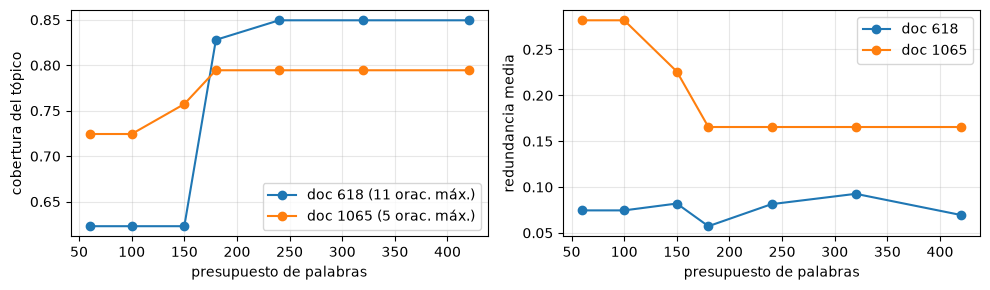

In [10]:
filas = []
for budget in [60, 100, 150, 180, 240, 320, 420]:
    for d in [1065, 618]:
        sm = summarize_doc(d, ix=ix, word_budget=budget)
        filas.append({"doc": d, "budget": budget, "compression": sm.stats["compression"],
                      "coverage": sm.stats["coverage"], "sentences": sm.stats["n_selected"],
                      "redundancy": sm.stats["redundancy"]})
df = pd.DataFrame(filas)
display(df.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for d, grupo in df.groupby("doc"):
    axes[0].plot(grupo.budget, grupo.coverage, marker="o", label=f"doc {d} ({grupo.sentences.max()} orac. máx.)")
    axes[1].plot(grupo.budget, grupo.redundancy, marker="o", label=f"doc {d}")
axes[0].set_xlabel("presupuesto de palabras"); axes[0].set_ylabel("cobertura del tópico")
axes[1].set_xlabel("presupuesto de palabras"); axes[1].set_ylabel("redundancia media")
for ax in axes:
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

## 10. Resumen multi-documento por año (módulo 5, temario 4.6)

Un año de un presidente son 87-308 discursos y ~100.000 palabras: resumirlos requiere agrupar,
resumir y fusionar.

1. **Agrupamiento temático**: k-means sobre las filas L2 de `w_global` (equivale a k-means esférico).
   `k = clip(round(√(n/4)), 3, 8)`. Los grupos de un solo documento se reasignan al centroide más
   cercano.
2. **Etiquetas**: los términos con mayor `df·idf` dentro del grupo, excluyendo los términos
   genéricos del año (aparecen en ≥ 40 % de los documentos) y los que contienen dígitos.
3. **Resúmenes individuales**: de cada grupo se toman hasta 3 documentos **medoides** (los más
   cercanos a su centroide) y se resume cada uno con 2 oraciones.
4. **Fusión + MMR**: las oraciones se puntúan juntas (híbrido del módulo 4, IDF global) y se
   seleccionan con MMR, con **cuota proporcional al tamaño del grupo** (método de Hare) y un
   presupuesto de 400 palabras.
5. **Tópicos comunes**: términos compartidos por varios grupos, ordenados por nº de grupos y peso.

In [11]:
from rat_scripts import (cluster_documents, docs_for_year, fuse_year,
                         prepare_year, year_availability)
from rat_scripts.evaluate_multidoc import (aggregate, key_topic_recall,
                                           load_year_gold, run_benchmark)

avail = pd.DataFrame(year_availability(ix))
display(avail[avail.docs >= 30].sort_values(["speaker", "year"], ignore_index=True))

docs_2023 = docs_for_year(ix, 2023, "Pedro Sánchez")
M = ix.w_global[docs_2023]
S = np.asarray((M @ M.T).todense())
iu = np.triu_indices(len(docs_2023), 1)
print(f"Sánchez 2023: {len(docs_2023)} discursos · similitud coseno media {S[iu].mean():.3f} "
      f"· q10 {np.quantile(S[iu], 0.10):.3f} · q90 {np.quantile(S[iu], 0.90):.3f}")

f23 = prepare_year(ix, 2023, "Pedro Sánchez", verbose=True)
display(pd.DataFrame([{"grupo": g.group_id, "docs": g.size, "etiqueta": g.label,
                       "términos": ", ".join(g.top_terms[:5])} for g in f23.groups]))
print("unidades fusionadas:", len(f23.units), "· palabras del año:", f23.words_original)

,speaker,year,docs
0,Andrés Manuel López Obrador,2019,552
1,Andrés Manuel López Obrador,2020,439
2,Andrés Manuel López Obrador,2021,365
3,Andrés Manuel López Obrador,2022,361
4,Andrés Manuel López Obrador,2023,308
5,Andrés Manuel López Obrador,2024,248
6,Javier Milei,2024,87
7,Javier Milei,2025,69
8,Pedro Sánchez,2018,121
9,Pedro Sánchez,2019,137


Sánchez 2023: 129 discursos · similitud coseno media 0.213 · q10 0.084 · q90 0.374


  grupo 0 ( 49 docs): reindustrializ, innov, apuest, profesional, adapt, situ
  grupo 1 ( 43 docs): rotatori, celac, brusel, zelenski, semestr, reindustrializ
  grupo 2 ( 14 docs): señori, interprofesional, parlamentari, revaloriz, ipc, gamarr
  grupo 3 ( 12 docs): zelenski, ucranian, durader, rus, municion, agresor
  grupo 4 (  8 docs): ham, palestin, gaz, rehen, israeli, israel
  grupo 5 (  3 docs): aziz, ithmar, marruec, xii, rabat, cofid


,grupo,docs,etiqueta,términos
0,0,49,reindustrializ · innov · apuest · profesional,"reindustrializ, innov, apuest, profesional, adapt"
1,1,43,rotatori · celac · brusel · zelenski,"rotatori, celac, brusel, zelenski, semestr"
2,2,14,señori · interprofesional · parlamentari · revaloriz,"señori, interprofesional, parlamentari, revaloriz, ipc"
3,3,12,zelenski · ucranian · durader · rus,"zelenski, ucranian, durader, rus, municion"
4,4,8,ham · palestin · gaz · rehen,"ham, palestin, gaz, rehen, israeli"
5,5,3,aziz · ithmar · marruec · xii,"aziz, ithmar, marruec, xii, rabat"


unidades fusionadas: 36 · palabras del año: 317442


Cada grupo aporta `k·n_g/n` oraciones (redondeo por mayor resto), con mínimo 1 para los grupos que
son ≥ 5 % de los documentos y 0 para los anecdóticos (< 0,5 oraciones esperadas). Así no entra una
ceremonia de entrega de medallas, pero un tema de 10-13 discursos (la DANA, Acapulco) sí puede
aparecer.

In [12]:
s23 = fuse_year(ix, f23)
print(s23.text)

display(pd.DataFrame([{"grupo": g["group_id"], "docs": g["size"], "etiqueta": g["label"],
                       "oraciones": g["selected"]} for g in s23.groups]))
display(pd.Series({k: round(v, 4) if isinstance(v, float) else v
                   for k, v in s23.stats.items()
                   if k not in ("doc_ids", "per_group_selected")}))

Yo creo que en estos últimos años hemos demostrado que España no tiene que elegir entre crear empleo o mejorar las condiciones de los trabajadores y trabajadoras del mundo. Por tanto, creo que es imperativo para todas las fuerzas políticas el renovar el Consejo General del Poder Judicial en el año 2024. Y en ese sentido, si el Partido Popular considera que es necesario que interceda, que medie la Comisión Europea en esta cuestión, nosotros encantados. Creo que podamos dar ese impulso transformador que necesita Europa antes de que lleguemos a las elecciones europeas del año 2024 y vamos a poner todo nuestro empeño porque en efecto sigamos haciendo avanzar al conjunto de la Unión Europea. Pero en mi opinión, lo más importante, y a lo que tenemos que dar respuesta en los próximos años es qué tipo de Unión Europea queremos. Por eso, lo primero que le he transmitido a la presidenta de la Comisión y al Colegio de Comisarios es que el Gobierno y el pueblo de España van a cumplir con su deber,

,grupo,docs,etiqueta,oraciones
0,0,49,reindustrializ · innov · apuest · profesional,2
1,1,43,rotatori · celac · brusel · zelenski,5
2,2,14,señori · interprofesional · parlamentari · revaloriz,2
3,3,12,zelenski · ucranian · durader · rus,1
4,4,8,ham · palestin · gaz · rehen,1
5,5,3,aziz · ithmar · marruec · xii,0


n_docs                  129
n_groups                  6
n_units                  36
n_selected               11
words_original       317442
words_summary           381
compression          0.0012
reduction            0.9988
coverage             0.2454
theme_coverage       0.9767
redundancy           0.0798
mean_sent_words     34.6364
docs_represented          9
idf_mode             global
dtype: object

### Los otros casos de referencia

Sánchez 2024, AMLO 2023 y Milei 2024, con el mismo pipeline:

In [13]:
casos = [("Pedro Sánchez", 2024), ("Andrés Manuel López Obrador", 2023), ("Javier Milei", 2024)]
for speaker, year in casos:
    sm = fuse_year(ix, prepare_year(ix, year, speaker))
    print("=" * 110)
    print(f"{speaker} · {year} · grupos={sm.stats['n_groups']} · oraciones={sm.stats['n_selected']} "
          f"· palabras={sm.stats['words_summary']} · temas cubiertos={sm.stats['theme_coverage']:.0%}")
    print(sm.text)

Pedro Sánchez · 2024 · grupos=6 · oraciones=11 · palabras=377 · temas cubiertos=97%
Yo creo que va a ser una gran oportunidad para seguir caminando en esa hoja de ruta compartida entre España y China. Queremos que España, que también India, trabajen conjuntamente para abordar los grandes retos globales, reforzar también nuestra relación entre la India y la Unión Europea que, como saben, el próximo año, en el año 2025 va a cumplir un aniversario muy especial en sus relaciones estratégicas. Con esa intención, con la de compartir ese crecimiento económico inclusivo y socialmente justo, hoy vamos a firmar, junto con el presidente Boric, la renovación de la alianza estratégica entre Chile y España para reforzar nuestra relación bilateral en ese horizonte compartido por ambos Gobiernos. El nuevo Acuerdo Marco Avanzado Chile y Unión Europea, firmado en diciembre del año 2023 bajo la Presidencia española del Consejo de la Unión Europea y aprobado la semana pasada en el Parlamento Europeo, repr

Andrés Manuel López Obrador · 2023 · grupos=8 · oraciones=12 · palabras=400 · temas cubiertos=92%
Vamos a ir avanzando, pero donde ya de esos 15 estados, donde empezamos, primero, ya tenemos resuelto casi al 100 por ciento el abasto, ahora te lo voy a probar, de acuerdo al informe que presentamos aquí incluso el mismo martes. Hay que decir que en el Poder Judicial trabajan 55 mil personas y solamente mil 700 reciben alimentos por más de 300 millones de pesos al año. La campaña de medios aquí no termina, porque ahora se fueron contra la cancelación de 13 fideicomisos del Poder Judicial. Por eso, qué voy a estar yo pensando que vamos a transformar a México con el apoyo de los potentados, que vamos a transformar a México con el apoyo de los políticos corruptos, que vamos a transformar a México con los comentaristas de radio, famosos que se han vuelto inmensamente ricos, qué voy a estar pensando yo que vamos a transformar a México con el apoyo de Krauze, de Aguilar Camín. Vamos a seguir ta

Javier Milei · 2024 · grupos=5 · oraciones=10 · palabras=400 · temas cubiertos=97%
De ser el país más rico del mundo, cuando abrazamos las ideas de la libertad a ser un país donde 6 de cada 10 argentinos son pobres, mientras la mayoría de los políticos – como muchos de ustedes – son ricos. Luego de más de cien años de insistir con un modelo empobrecedor y habiendo olvidado casi por completo las ideas que hicieron grande, a nuestro país, los últimos 20 años han sido, particularmente, un desastre económico; una orgía de gasto público; emisión descontrolada, que tuvo como resultado la peor herencia que ningún gobierno en la historia argentina haya recibido jamás. Para eso estamos aquí hoy, para establecer entre nosotros y junto a la sociedad un pacto de caballeros en torno a estos pilares, y para decir ante todos los argentinos de bien que reclamaron un cambio de rumbo con su voto que una Argentina distinta es imposible haciendo lo mismo de siempre. A pesar de haber sido una demanda histó

### Evaluación (4.5) del resumen anual

ROUGE contra una referencia humana de ~70 palabras (el resumen tiene ~390: ROUGE F1 castiga la
longitud, sirve para comparar variantes, no como valor absoluto) y **recall de tópicos clave**
7-8 por caso. Se comparan variantes del pipeline y una selección aleatoria como suelo.

In [14]:
gold_year = load_year_gold()
rows, base = run_benchmark(ix, gold_year, return_summaries=True)
agg = aggregate(rows)
display(pd.DataFrame(agg).round(3))

piv = pd.DataFrame(rows).pivot_table(index=["speaker", "year"], columns="variant",
                                     values="topic_recall").round(2)
display(piv)

,variant,n_cases,rouge1,rouge2,rougeL,topic_recall,centroid_similarity,theme_coverage,compression,redundancy,words_summary,n_groups,docs_represented
0,base (global),4,0.104,0.031,0.058,0.562,0.204,0.959,0.001,0.067,389.50,6.25,8.750
1,idf blend,4,0.105,0.030,0.060,0.562,0.205,0.959,0.001,0.056,392.25,6.25,8.750
2,idf local,4,0.100,0.030,0.059,0.562,0.208,0.959,0.001,0.049,391.50,6.25,8.250
3,sin agrupamiento,4,0.095,0.021,0.073,0.344,0.147,1.000,0.001,0.144,344.75,1.00,7.500
4,sin cuotas,4,0.094,0.023,0.061,0.406,0.230,0.647,0.001,0.089,393.25,6.25,9.500
5,cuotas min-1,4,0.113,0.033,0.065,0.625,0.203,0.991,0.001,0.063,389.50,6.25,9.000
6,aleatorio,4,0.081,0.015,0.046,0.510,0.236,0.908,0.001,0.038,395.75,6.25,9.833


variant                           aleatorio  base (global)  cuotas min-1  idf blend  idf local  sin agrupamiento  sin cuotas
speaker                     year                                                                                            
Andrés Manuel López Obrador 2023       0.58           0.62          0.75       0.62       0.62              0.50        0.62
Javier Milei                2024       0.54           0.62          0.62       0.62       0.62              0.50        0.38
Pedro Sánchez               2023       0.46           0.50          0.62       0.50       0.50              0.25        0.25
                            2024       0.46           0.50          0.50       0.50       0.50              0.12        0.38

Lectura: el agrupamiento y las cuotas son lo que más aporta (sin agrupamiento el recall de tópicos
cae de 0.56 a 0.38); el IDF global y el mezclado empatan (el local pierde algo) y el azar sobre el
mismo material cubre tópicos frecuentes pero produce resúmenes sin estructura y con peor ROUGE.
La variante "cuotas min-1" cubre más temas pequeños a costa de colar alguna oración de ceremonia.

In [15]:
item = [g for g in gold_year if g["speaker"] == "Pedro Sánchez" and g["year"] == "2023"][0]
sm = dict(((s.speaker, s.date), s) for _, s in base)[("Pedro Sánchez", "2023")]
print("REFERENCIA HUMANA:\n", item["reference"])
print("\nRESUMEN DEL SISTEMA:\n", sm.text)

recall, hits = key_topic_recall(sm.text, item["key_topics"])
print(f"\nrecall de tópicos: {recall:.2f}")
display(pd.DataFrame(hits, columns=["tópico", "cubierto"]))

REFERENCIA HUMANA:
 Sánchez centró 2023 en la presidencia española del Consejo de la Unión Europea: cumbre de Granada, apoyo a Ucrania y respuesta humanitaria en Gaza. En el plano interior defendió la reindustrialización, la ley de vivienda y la renovación del CGPJ, y cerró acuerdos con Marruecos. La investidura y la convivencia en Cataluña marcaron el debate parlamentario.

RESUMEN DEL SISTEMA:
 Yo creo que en estos últimos años hemos demostrado que España no tiene que elegir entre crear empleo o mejorar las condiciones de los trabajadores y trabajadoras del mundo. Por tanto, creo que es imperativo para todas las fuerzas políticas el renovar el Consejo General del Poder Judicial en el año 2024. Y en ese sentido, si el Partido Popular considera que es necesario que interceda, que medie la Comisión Europea en esta cuestión, nosotros encantados. Creo que podamos dar ese impulso transformador que necesita Europa antes de que lleguemos a las elecciones europeas del año 2024 y vamos a poner

,tópico,cubierto
0,presidencia de la UE,True
1,Ucrania / Zelenski,True
2,Gaza / Palestina,True
3,Marruecos,False
4,reindustrialización,False
5,vivienda,False
6,CGPJ / poder judicial,True
7,Cataluña / investidura,False


## 11. Un texto cualquiera, fuera del corpus

Si el texto no está indexado, el IDF se calcula **localmente** sobre sus propias oraciones. Mismo
pipeline, sin tocar el índice.

In [16]:
texto = (
    "La inflación en Argentina se desaceleró en marzo, según informó el Instituto Nacional de "
    "Estadística y Censos. El índice de precios al consumidor registró una suba del 3,7 por ciento "
    "mensual, la cifra más baja desde octubre de 2023. El Ministerio de Economía atribuyó el "
    "resultado a la disciplina fiscal y a la reducción del déficit. Sin embargo, los salarios "
    "reales siguen por debajo de los niveles de hace un año y la pobreza afecta a cerca del 40 por "
    "ciento de la población. Analistas privados advirtieron que la desinflación se apoya en la "
    "recesión y en el atraso del tipo de cambio. El Gobierno sostuvo que la recuperación llegará en "
    "el segundo semestre y que la prioridad es bajar el riesgo país. El Fondo Monetario "
    "Internacional celebró el ajuste y anticipó nuevas revisiones del programa. La oposición "
    "reclamó medidas para los sectores más vulnerables y criticó el recorte de subsidios. El Banco "
    "Central acumuló reservas por tercera semana consecutiva y el dólar paralelo cedió un 2 por "
    "ciento. Economistas coincidieron en que la clave será sostener el superávit fiscal sin frenar "
    "la actividad."
)
sm = summarize_text(texto, title="Inflación y salarios en Argentina", ratio=0.25,
                    use_global_idf=False)
print(sm.pretty(width=100))
print({k: round(v, 3) for k, v in sm.stats.items() if isinstance(v, (int, float))})

· hybrid
El índice de precios al consumidor registró una suba del 3,7 por ciento mensual, la cifra más baja
desde octubre de 2023. Sin embargo, los salarios reales siguen por debajo de los niveles de hace un
año y la pobreza afecta a cerca del 40 por ciento de la población. El Banco Central acumuló reservas
por tercera semana consecutiva y el dólar paralelo cedió un 2 por ciento.
{'n_units': 10, 'n_selected': 3, 'words_original': 184, 'words_summary': 69, 'compression': 0.375, 'reduction': 0.625, 'coverage': 0.152, 'redundancy': 0.049, 'mean_sent_words': 23.0}


## 12. Limitaciones

1. **Es extractivo**: nunca reescribe ni fusiona oraciones. Las oraciones que empiezan a media idea
   (`"Muestra que la vacuna…"`) o los cierres protocolares pueden colarse; se penalizan, no se
   eliminan, porque eliminarlas perdería contenido.
2. **Cinco referencias** es una muestra pequeña para ROUGE; las diferencias entre métodos rondan
   0.02-0.03 F1 y no son significativas. La comparación sirve para descartar métodos, no para
   coronar uno.
3. **El "hecho principal" no se detecta**: en el discurso de Milei el caso de Nahuel Gallo (la
   noticia del día) pierde frente a oraciones más "centrales" léxicamente. Sin supervisión no hay
   forma barata de saber qué oración es noticia.
4. **Transcripciones**: las mañaneras de AMLO traen 18k palabras y oraciones de 60 palabras; el
   presupuesto de 180 palabras produce resúmenes muy comprimidos (≈1 % del original).
5. **La cobertura es conservadora**: se mide sobre los 20 términos de mayor peso del documento. En un
   texto de 10 oraciones cada término aparece en una sola oración, así que una cobertura de 0.15 no
   significa un mal resumen; en los discursos de ~400 palabras la cobertura ronda 0.71-0.83.
6. **Resumen anual**: las etiquetas de los grupos son stems (`reindustrializ`, `fentanil`), no
   títulos editoriales; los grupos pequeños (3-13 discursos) pueden quedar fuera por la cuota, y las
   mañaneras de AMLO tienen un agrupamiento débil porque el formato es homogéneo. Los resúmenes
   anuales son de ~390 palabras: cubren temas, no detalle.

In [17]:
from pathlib import Path
for p in sorted(config.ARTIFACTS.iterdir()):
    print(f"{p.name:24s} {p.stat().st_size/1024:8.1f} KB")

eval.json                    40.0 KB
multidoc                      4.0 KB
summaries_demo.jsonl         48.0 KB
tables.md                    12.7 KB
